# 10. Accuracy required of the halo layer

This notebook follows Sec. 4.4 of Paper I.
How far does a wrong halo ingredient (mass function, bias or concentration) move the cosmology a forecast infers, and how accurate must each be?
We first compute the answer ourselves for the cluster counts of notebook 09, then read the results of the three studies behind Fig. 13 from the tutorial data bundle and redraw the figure.
The studies for projected clustering and for the angular power spectra free the galaxy–halo connection and dozens of nuisance parameters; they ran on a cluster and are not recomputed here.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import json

from matplotlib.ticker import FuncFormatter, NullLocator

from ggah_mod.cosmology import PLANCK18, sigma8

import _forecast as F

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


## The bias of a forecast

The analysis uses a wrong ingredient while the data follow the default, so the model differs from the truth by $\Delta\mathbf{d}$.
To first order the best fit moves from the truth by (Eq. 49)

$$\delta\boldsymbol\theta = -\left(F + F^{\rm prior}\right)^{-1}\frac{\partial\mathbf{d}^{\rm T}}{\partial\boldsymbol\theta}\mathsf{C}^{-1}\Delta\mathbf{d},$$

with $F$, $F^{\rm prior}$ and $\mathsf{C}$ those of the forecast.
We quote $\beta = \delta S_8/\sigma(S_8)$, and take $|\beta| = 0.3$ as the point where an error starts to bias the cosmology: a shift of $0.3\sigma$ lowers the coverage of the 68 per cent interval to 66 per cent.
A fractional error $\epsilon$, constant in mass, gives the tolerance $\epsilon_{\max}$ at which $|\beta| = 0.3$.

## Computing it for the cluster counts

A constant error $\epsilon$ in ${\rm d}n/{\rm d}M$ multiplies every count by $1+\epsilon$, so $\Delta\mathbf{d} = \epsilon\mathbf{N}$.
We reuse the counts, Jacobian and covariance of notebook 09, in flat $\Lambda$CDM with the BBN and $n_{\rm s}$ priors, and $S_8 = \sigma_8(\Omega_{\rm m}/0.3)^{1/2}$.

In [2]:
st = F._hmf_setup()
P5, t0x = F._HMF_P, st["t0"]
npar = len(P5)
emu = st["emu"]
kk = jnp.asarray(np.logspace(-4, 2, 512))
s80 = float(sigma8(emu.pk(kk, 0.0, PLANCK18), kk))
g8 = F._fs_sigma8_gradient(t0x, F._HMF_PX, emu=emu)[:npar]
gS8 = g8 * np.sqrt(t0x[0] / 0.3)
gS8[0] += 0.5 * s80 / np.sqrt(0.3 * t0x[0])            # d S8 / d theta

tol_here = []
for i, th in enumerate(F._HMF_THRESH):
    J = st["J"][i][:, :npar]
    Cinv = np.linalg.inv(st["C"][i][1])
    cov = np.linalg.inv(J.T @ Cinv @ J + F._hmf_prior(P5, t0x[:npar]))
    dtheta = -cov @ J.T @ Cinv @ st["n0"][i].ravel()          # per unit epsilon
    beta_per_eps = float(gS8 @ dtheta) / float(np.sqrt(gS8 @ cov @ gS8))
    tol_here.append(0.3 / abs(beta_per_eps))
    print(f"M > {th:.0e}: beta = {beta_per_eps * 0.01:+.2f} for a 1% error; tolerance {100 * tol_here[-1]:.2f}%")

/home/jcomparat/software/ggah_mod/ggah_mod/covariance/__init__.py:47: WorkInProgressWarning: ggah_mod.covariance is work in progress. Layers 3 to 6 of ggah_mod (sectors, spectra, observables, covariance) and its interfaces are released as tested code ahead of their verification; their interface and results may change. Every layer is documented at https://ggah-mod.readthedocs.io.
  warn_work_in_progress(__name__)


M > 5e+13: beta = -0.55 for a 1% error; tolerance 0.55%
M > 1e+14: beta = -0.40 for a 1% error; tolerance 0.75%
M > 3e+14: beta = -0.20 for a 1% error; tolerance 1.48%
M > 5e+14: beta = -0.12 for a 1% error; tolerance 2.57%


## The three studies

The bundle holds the results of the three studies of Sec. 4.4: the counts (the computation above, with swaps of one fit for another and errors localised in mass), the abundance and projected clustering of galaxies $\bar n$ and $w_{\rm p}$ (Tier 1, against the scale cut $r_{\rm p,min}$), and the angular power spectra of galaxies and shear in one shell (T1 without the shear, T2 with it, against $k_{\max}$).
Each records, per cut, $\sigma(S_8)$, $\beta$ for each swap, and the constant-error tolerance of each ingredient.

In [3]:
load = lambda name: json.load(open(T.data_path(name)))
c = load("halo_req/counts/results.json")
t = load("halo_req/tier1/results.json")
j = load("halo_req/joint_closure/results_C1+SSC.json")
thr = c["threshold"]
crow = [c["per_threshold"][k] for k in c["per_threshold"]]
cx = np.asarray(c["thresholds"])
trow = t["per_cut"]
tx = np.asarray([r["rp_min"] for r in trow])
jrow = {tier: [r for r in j["per_cut"] if r["tier"] == tier] for tier in j["tiers"]}
jx = np.asarray([r["k_max"] for r in jrow["T2"]])
print(f"|beta| threshold {thr}; counts at {cx}; Tier 1 at {tx.size} cuts; joint shell at k_max = {jx.tolist()}")
print("counts tolerance on dn/dM: here " + ", ".join(f"{100 * x:.2f}%" for x in tol_here)
      + ";  study " + ", ".join(f"{100 * x['tolerance_const']['S8']:.2f}%" for x in crow))

|beta| threshold 0.3; counts at [5.e+13 1.e+14 3.e+14 5.e+14]; Tier 1 at 30 cuts; joint shell at k_max = [0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0]
counts tolerance on dn/dM: here 0.55%, 0.75%, 1.48%, 2.57%;  study 0.55%, 0.75%, 1.48%, 2.57%


The tolerances computed above and those of the study agree to the precision of the two runs: the study used the same counts on the paper's grids.
Swaps of one fit for another give the bias of a realistic error.

In [4]:
DRAW = (("hydro", "dndm", "baryons (bocquet16 hydro/DMO)"), ("despali16", "dndm", "despali16"),
        ("b_sheth01", "bias", "sheth01"), ("bias@200c", "bias", "tinker10 at 200c"), ("c_duffy08", "conc", "duffy08"))
HUE = {"dndm": "#2a78d6", "bias": "#eb6834", "conc": "#1baf7a"}
TEXI = {"dndm": r"$\mathrm{d}n/\mathrm{d}M$", "bias": r"$b$", "conc": r"$c$"}


def beta(rows, name):
    return np.array([r["swaps"][name]["beta"]["S8"] for r in rows])


i01 = int(np.argmin(np.abs(np.log(tx / 0.1))))
print("Tier 1 at r_p,min = 0.1 Mpc/h: " + "  ".join(f"{n} {trow[i01]['swaps'][n]['beta']['S8']:+.2f}" for n, _, _ in DRAW))
small = tx <= 1.0
print("Tier 1 tolerance on b below 1 Mpc/h: "
      f"{100 * min(r['tolerance_const']['bias']['S8'] for r, s in zip(trow, small) if s):.2f}"
      f"-{100 * max(r['tolerance_const']['bias']['S8'] for r, s in zip(trow, small) if s):.2f}%")
r1 = jrow["T2"][list(jx).index(1.0)]
print(f"T2 at k_max = 1: sigma(S8)/S8 = {r1['S8_rel']:.1e}; sheth01 {r1['swaps']['b_sheth01']['beta']['S8']:+.1f}, "
      f"200c {r1['swaps']['bias@200c']['beta']['S8']:+.1f}")

Tier 1 at r_p,min = 0.1 Mpc/h: hydro -1.58  despali16 -1.62  b_sheth01 -10.10  bias@200c -5.73  c_duffy08 -0.49
Tier 1 tolerance on b below 1 Mpc/h: 0.33-0.44%
T2 at k_max = 1: sigma(S8)/S8 = 8.2e-03; sheth01 -18.4, 200c -11.8


## The figure

Fig. 13 of the paper.
Top: $\beta$ for each swap against the mass threshold, the scale cut and $k_{\max}$, on a `symlog` axis linear inside $|\beta| < 0.3$ (shaded).
Bottom: the constant error in each ingredient that shifts $S_8$ by $0.3\sigma$; in panel (f), with the shear (solid) and without it (dotted).

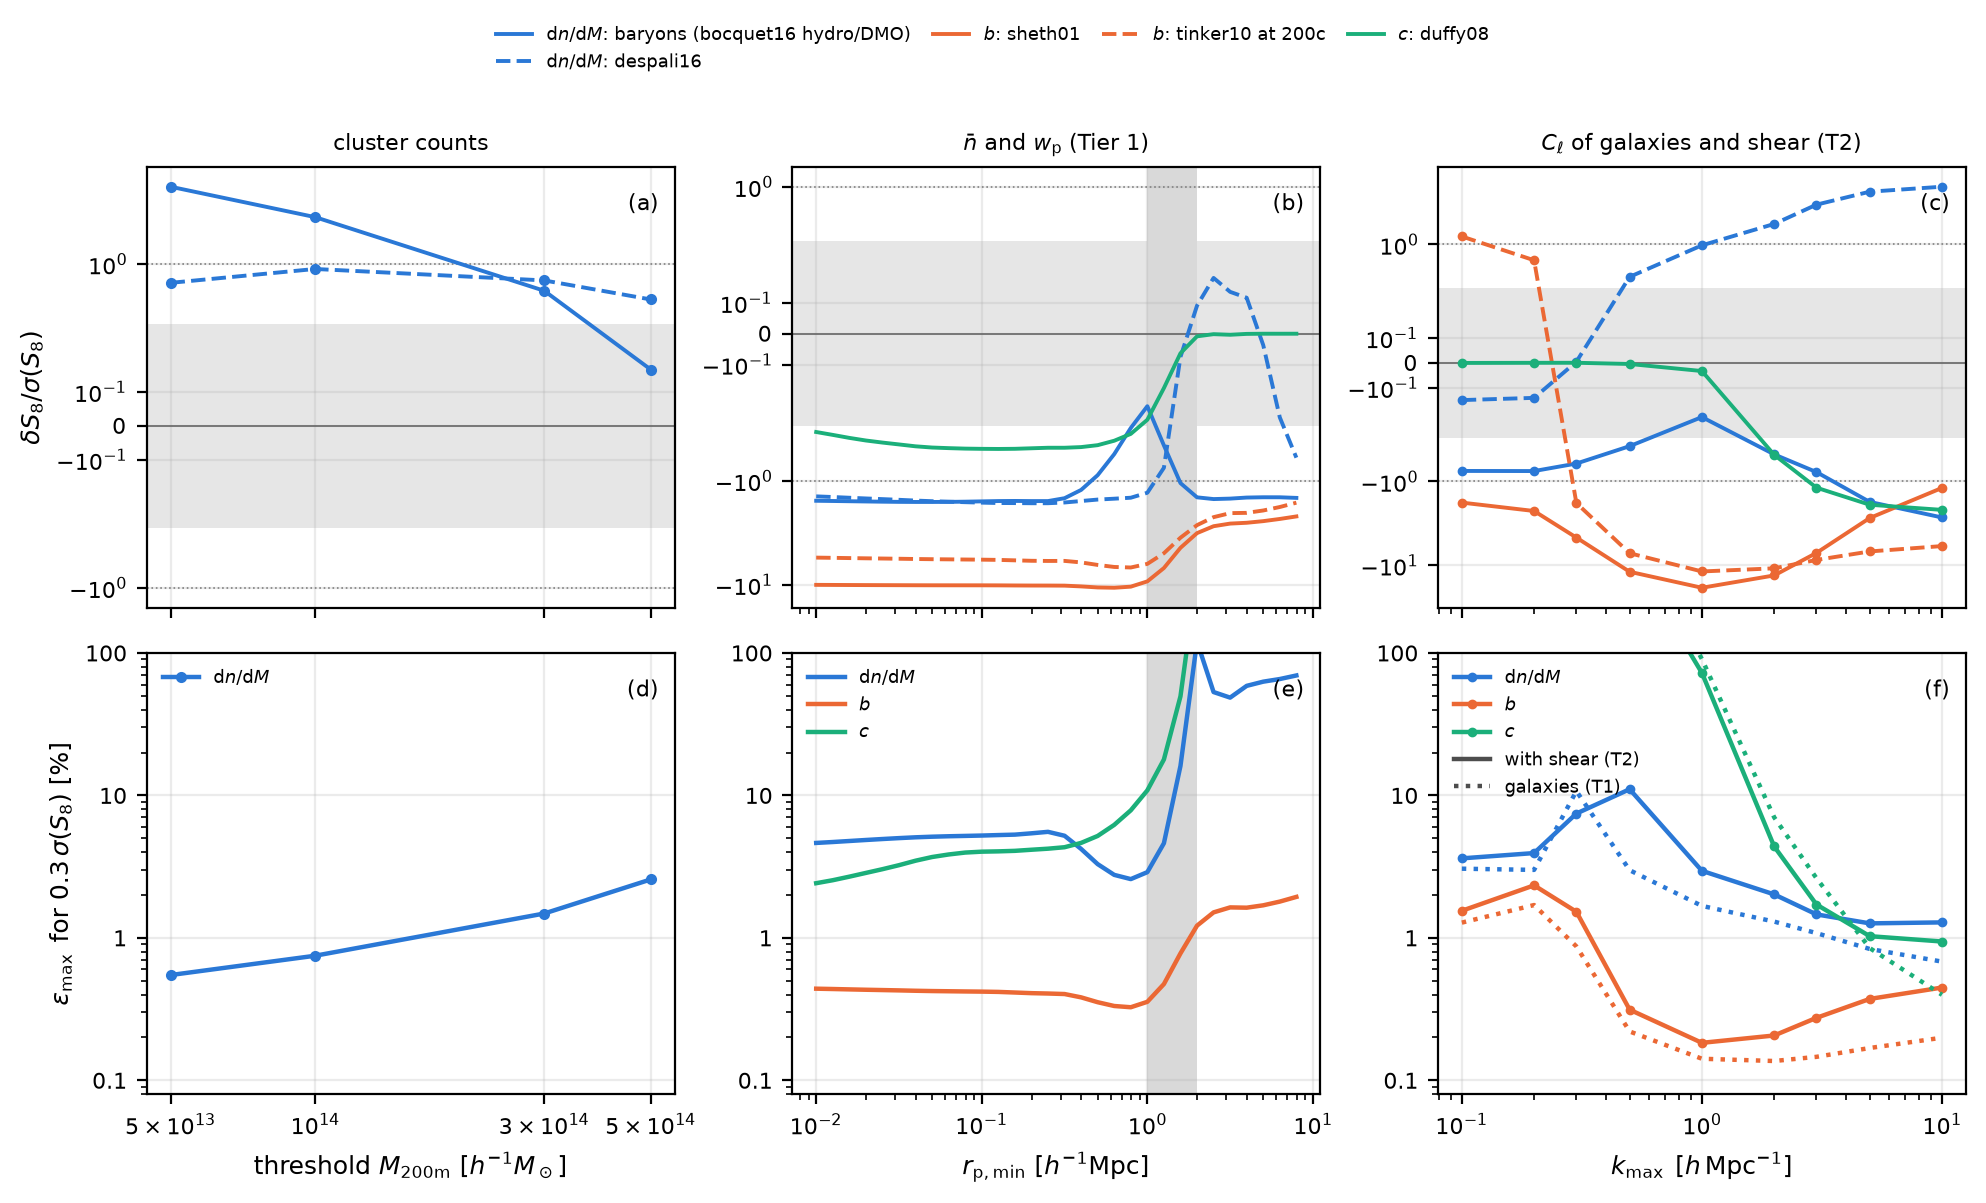

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(10.0, 6.0), sharex="col")
for ax in axs[0]:
    ax.axhspan(-thr, thr, color="0.9", lw=0, zorder=0)
    ax.axhline(0.0, color="0.4", lw=0.6)
    for y in (-1.0, 1.0):
        ax.axhline(y, color="0.5", lw=0.6, ls=":")
    ax.set_yscale("symlog", linthresh=thr, linscale=0.8)
styles = {"dndm": ["-", "--", ":"], "bias": ["-", "--"], "conc": ["-"]}
used = {k: 0 for k in styles}
for name, ing, lab in DRAW:
    kw = dict(color=HUE[ing], ls=styles[ing][used[ing]], lw=1.4)
    used[ing] += 1
    if ing == "dndm":
        axs[0, 0].plot(cx, beta(crow, name), marker="o", ms=3, **kw)
    axs[0, 1].plot(tx, beta(trow, name), label=f"{TEXI[ing]}: {lab}", **kw)
    axs[0, 2].plot(jx, beta(jrow["T2"], name), marker="o", ms=2.5, **kw)
axs[0, 0].set_ylabel(r"$\delta S_8/\sigma(S_8)$")
fig.legend(*axs[0, 1].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=6.5, frameon=False,
           bbox_to_anchor=(0.5, 1.0), columnspacing=1.2)
axs[1, 0].plot(cx, [100 * x["tolerance_const"]["S8"] for x in crow], color=HUE["dndm"], marker="o", ms=3, label=TEXI["dndm"])
for ing in ("dndm", "bias", "conc"):
    axs[1, 1].plot(tx, [100 * r["tolerance_const"][ing]["S8"] for r in trow], color=HUE[ing], label=TEXI[ing])
    for tier, ls in (("T2", "-"), ("T1", ":")):
        axs[1, 2].plot(jx, [100 * r["tolerance_const"][ing]["S8"] for r in jrow[tier]], color=HUE[ing], ls=ls,
                       marker="o" if tier == "T2" else None, ms=2.5, label=TEXI[ing] if tier == "T2" else None)
axs[1, 2].plot([], [], color="0.3", ls="-", label="with shear (T2)")
axs[1, 2].plot([], [], color="0.3", ls=":", label="galaxies (T1)")
for ax in axs[1]:
    ax.set_yscale("log")
    ax.set_ylim(0.08, 100)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.legend(fontsize=6.5, frameon=False, loc="upper left")
axs[1, 0].set_ylabel(r"$\epsilon_{\max}$ for $0.3\,\sigma(S_8)$ [%]")
axs[1, 0].set_xlabel(r"threshold $M_{200{\rm m}}\ [h^{-1}M_\odot]$")
axs[1, 1].set_xlabel(r"$r_{\rm p,min}\ [h^{-1}\mathrm{Mpc}]$")
axs[1, 2].set_xlabel(r"$k_{\max}\ [h\,\mathrm{Mpc}^{-1}]$")
for ax in axs[:, 0]:
    ax.set_xscale("log")
    ax.set_xticks(cx, [r"$5\times10^{13}$", r"$10^{14}$", r"$3\times10^{14}$", r"$5\times10^{14}$"])
    ax.xaxis.set_minor_locator(NullLocator())
for ax in axs[:, 1]:
    ax.set_xscale("log")
    ax.axvspan(1.0, 2.0, color="0.85", lw=0, zorder=0)
for ax in axs[:, 2]:
    ax.set_xscale("log")
axs[0, 0].set_title("cluster counts", fontsize=8)
axs[0, 1].set_title(r"$\bar n$ and $w_{\rm p}$ (Tier 1)", fontsize=8)
axs[0, 2].set_title(r"$C_\ell$ of galaxies and shear (T2)", fontsize=8)
for ax, s_ in zip(axs.ravel(), "abcdef"):
    ax.text(0.97, 0.94, f"({s_})", transform=ax.transAxes, ha="right", va="top", fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.92))
T.save_figure(fig, "fig_halo_requirements")

## Check against the paper

In [6]:
quoted = [(f"counts tolerance >{th:.0e}", crow[i]["tolerance_const"]["S8"], p)
          for i, (th, p) in enumerate(zip(F._HMF_THRESH, (0.0055, 0.0075, 0.0148, 0.0257)))]
quoted += [("counts despali16 >5e13", crow[0]["swaps"]["despali16"]["beta"]["S8"], 0.69),
           ("counts baryons >5e13", crow[0]["swaps"]["hydro"]["beta"]["S8"], 4.7),
           ("Tier 1 sheth01 at 0.1", trow[i01]["swaps"]["b_sheth01"]["beta"]["S8"], -10.1),
           ("Tier 1 200c at 0.1", trow[i01]["swaps"]["bias@200c"]["beta"]["S8"], -5.7),
           ("Tier 1 duffy08 at 0.1", trow[i01]["swaps"]["c_duffy08"]["beta"]["S8"], -0.49),
           ("T2 sigma(S8)/S8 at k=1", r1["S8_rel"], 8.2e-3),
           ("T2 sheth01 at k=1", r1["swaps"]["b_sheth01"]["beta"]["S8"], -18.5),
           ("T2 200c at k=1", r1["swaps"]["bias@200c"]["beta"]["S8"], -11.8)]
quoted += [(f"live counts tolerance >{th:.0e}", tol_here[i], p)
           for i, (th, p) in enumerate(zip(F._HMF_THRESH, (0.0055, 0.0075, 0.0148, 0.0257)))]
bad = []
for label, here, paper in quoted:
    ok = abs(here / paper - 1) < 0.05
    print(f"{label:28s} here {here:+.3g}   paper {paper:+.3g}" + ("" if ok else "   <-- differs"))
    bad += [] if ok else [label]
assert not bad, bad
print("Sec. 4.4 reproduced")

counts tolerance >5e+13      here +0.00548   paper +0.0055
counts tolerance >1e+14      here +0.00749   paper +0.0075
counts tolerance >3e+14      here +0.0148   paper +0.0148
counts tolerance >5e+14      here +0.0257   paper +0.0257
counts despali16 >5e13       here +0.685   paper +0.69
counts baryons >5e13         here +4.72   paper +4.7
Tier 1 sheth01 at 0.1        here -10.1   paper -10.1
Tier 1 200c at 0.1           here -5.73   paper -5.7
Tier 1 duffy08 at 0.1        here -0.494   paper -0.49
T2 sigma(S8)/S8 at k=1       here +0.00815   paper +0.0082
T2 sheth01 at k=1            here -18.4   paper -18.5
T2 200c at k=1               here -11.8   paper -11.8
live counts tolerance >5e+13 here +0.00548   paper +0.0055
live counts tolerance >1e+14 here +0.00749   paper +0.0075
live counts tolerance >3e+14 here +0.0148   paper +0.0148
live counts tolerance >5e+14 here +0.0257   paper +0.0257
Sec. 4.4 reproduced


The fits shipped with this package differ by up to 12 per cent in $b(M)$ and by 2–8 per cent in ${\rm d}n/{\rm d}M$ where the counts test them, an order of magnitude above these tolerances.
The precision of the cosmological constraints from the clustering of galaxies on any scale, and from the counts above any threshold, is therefore limited by the halo layer rather than by the data.
Notebook 11 sizes the simulations that would lift the limit.

## Exercises

1. Compute $\beta$ for the counts when `tinker08` is replaced by `despali16` in the analysis: rebuild the counts with `H.dndm(..., model="despali16", delta_ratio=...)` (see notebook 05 for the conversion of the mass definition) and use their difference as $\Delta\mathbf{d}$. Compare with the bundle's `despali16` swap.
2. Localise the error: put $\epsilon$ only in one 0.5-dex window of mass and scan the window across the bins. Where are the counts most sensitive?
3. Double the covariance. By how much does every tolerance change, and why?

Next: notebook 11, the simulations a joint halo emulator needs.